<a href="https://colab.research.google.com/github/saumyashah11/TIH_data-pipeline/blob/backbone-benchmark/tih.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PIPELINE

## Agri Image Data Preprocessing Pipeline

**Project:** Plant Disease Classification System (TIH-IoT) · **Team:** Anushree & Saumya, NMIMS · **November 2026**

**Dataset:** PlantVillage (updated) — Kaggle: tushar5harma/plant-village-dataset-updated

This notebook implements blocks **1 to 4** of the end-to-end training architecture:

| Block | Stage | Implemented in |
|---|---|---|
| 1 | Data Collection — raw class-wise folders | Step 1 |
| 2 | Preprocessing — dedup, resize, normalise, augment, split | Steps 2 and 3 |
| 3 | Dataset Structure — processed_dataset/train, val, test | Step 3 |
| 4 | Data Loader — PyTorch Dataset + DataLoader | Step 4 |

Blocks 5 to 8 (transfer-learning model, two-stage training, evaluation, Grad-CAM++) consume the DataLoaders produced at the end of this notebook.

**Design principle:** nothing is deleted in place. Every rejected image is logged to CSV with its rejection reason, so the cleaning decisions stay auditable and reproducible (seed = 42).

In [ ]:
# =====================================================================
# STEP 0 | ENVIRONMENT SETUP + GLOBAL CONFIG
# =====================================================================

!pip -q install imagehash

import os, json, time, shutil, hashlib, random, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile, UnidentifiedImageError
from tqdm.auto import tqdm
import torch

warnings.filterwarnings("ignore")
# keep this False so truncated files RAISE and get quarantined instead of silently loading
ImageFile.LOAD_TRUNCATED_IMAGES = False

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)


class CFG:
    # ---- paths ------------------------------------------------------
    work_root      = Path("/content/agri")
    audit_root     = work_root / "audit"              # CSV / JSON / PNG artefacts
    processed_root = work_root / "processed_dataset"  # train / val / test

    # ---- image ------------------------------------------------------
    img_size   = 224        # CNN input size (ResNet34 / ResNet50 / MobileNetV2)
    store_size = 256        # stored at 256 so random/center crops stay lossless
    jpeg_q     = 95

    # ---- cleaning ---------------------------------------------------
    min_side             = 32     # reject anything smaller than this
    perceptual_dedup     = True   # dHash near-duplicate removal
    min_images_per_class = 20     # drop ultra-rare classes

    # ---- split ------------------------------------------------------
    train_frac, val_frac, test_frac = 0.80, 0.10, 0.10

    # ---- loader -----------------------------------------------------
    batch_size    = 32
    num_workers   = 2
    imagenet_mean = [0.485, 0.456, 0.406]
    imagenet_std  = [0.229, 0.224, 0.225]


for _p in (CFG.work_root, CFG.audit_root, CFG.processed_root):
    _p.mkdir(parents=True, exist_ok=True)

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

print("torch", torch.__version__, "| GPU:",
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU)")
print("work root:", CFG.work_root)

### Step 1 — Load the dataset from your own zip

Two ways, both in the next cell:

**A. Pick the file from your computer.** Leave **ZIP_PATH** empty and run the cell — a file picker opens and you choose the zip from your folder. Fine up to roughly 1 GB; the browser upload is slow and can drop above that.

**B. Point at a zip you already have.** Set **ZIP_PATH** to a path, e.g. a file dragged into the Colab **Files** pane (*/content/plantvillage.zip*) or one in Drive after mounting it:

    from google.colab import drive
    drive.mount("/content/drive")
    ZIP_PATH = "/content/drive/MyDrive/plantvillage.zip"

For anything over a GB, B is the reliable route — Drive, or the Files pane.

The cell extracts into **/content/agri/raw**, skipping entries that are already there (so a re-run costs nothing), refuses any archive entry that tries to write outside that folder, and then indexes every image taking the **immediate parent folder as the class label**. Mac *__MACOSX* junk and dotfiles are ignored.

Any folder layout works — flat class folders, or an archive already split into train/valid — because the author's split is discarded and we re-stratify in Step 3.

In [ ]:
# =====================================================================
# STEP 1 | LOAD THE DATASET FROM A ZIP  ->  raw index (path, class)
# =====================================================================

import zipfile

# Leave empty to open a file picker, or paste a path you already have:
#   "/content/plantvillage.zip"                        (Files pane)
#   "/content/drive/MyDrive/plantvillage.zip"          (after drive.mount)
ZIP_PATH = "/content/archive (10).zip"

RAW_ROOT = CFG.work_root / "raw"
RAW_ROOT.mkdir(parents=True, exist_ok=True)

if ZIP_PATH:
    zip_path = Path(ZIP_PATH)
    if not zip_path.exists():
        raise FileNotFoundError("No file at " + str(zip_path))
else:
    from google.colab import files
    print("Choose the dataset .zip from your folder ...")
    uploaded = files.upload()
    if not uploaded:
        raise RuntimeError("Nothing was uploaded. Re-run, or set ZIP_PATH instead.")
    name = list(uploaded)[0]
    zip_path = CFG.work_root / name
    src = Path.cwd() / name
    if src.resolve() != zip_path.resolve():
        shutil.move(str(src), str(zip_path))

DATASET = zip_path.name
print("archive:", zip_path, "|", round(zip_path.stat().st_size / 1e9, 3), "GB")

if not zipfile.is_zipfile(zip_path):
    raise RuntimeError(str(zip_path) + " is not a zip archive")

# ---- extract, refusing any entry that escapes RAW_ROOT --------------
root_abs = str(RAW_ROOT.resolve())
with zipfile.ZipFile(zip_path) as zf:
    members = [m for m in zf.infolist() if not m.is_dir()]
    for m in members:
        target = (RAW_ROOT / m.filename).resolve()
        if not str(target).startswith(root_abs):
            raise RuntimeError("unsafe path inside archive: " + m.filename)
    todo = [m for m in members if not (RAW_ROOT / m.filename).exists()]
    print("entries in archive:", format(len(members), ","),
          "| to extract:", format(len(todo), ","))
    for m in tqdm(todo, desc="extracting"):
        zf.extract(m, RAW_ROOT)

# ---- index every image; class label = immediate parent folder -------
rows = []
for p in RAW_ROOT.rglob("*"):
    if not p.is_file() or p.suffix.lower() not in IMG_EXT:
        continue
    if "__MACOSX" in p.parts or p.name.startswith("."):
        continue
    rows.append({"path": str(p), "class": p.parent.name})

raw_df = pd.DataFrame(rows)
if raw_df.empty:
    raise RuntimeError("No image files found under " + str(RAW_ROOT))

raw_df.to_csv(CFG.audit_root / "00_raw_index.csv", index=False)

print()
print("images found  :", format(len(raw_df), ","))
print("class folders :", raw_df["class"].nunique())
print()
display(raw_df["class"].value_counts().head(10).to_frame("images"))

archive: /content/archive (10).zip | 1.076 GB
entries in archive: 67,118 | to extract: 67,118


extracting:   0%|          | 0/67118 [00:00<?, ?it/s]


images found  : 67,118
class folders : 17



,images
class,
Healthy,20843
Bacterial Spot,6815
Black Rot,4844
Early Blight,4824
Late Blight,4738
Apple Scab,2520
Yellow Leaf Curl Virus,2451
Esca (Black Measles),2400
Northern Leaf Blight,2385


In [ ]:
# =====================================================================
# STEP 2a | INTEGRITY AUDIT  ->  unreadable / truncated / tiny / empty
# =====================================================================

def audit_one(row):
    p = Path(row["path"])
    rec = {"path": row["path"], "class": row["class"], "ok": False,
           "reason": "", "w": None, "h": None, "mode": None, "bytes": 0}
    try:
        rec["bytes"] = p.stat().st_size
        if rec["bytes"] == 0:
            rec["reason"] = "empty_file"
            return rec
        with Image.open(p) as im:      # pass 1 - header / structure
            im.verify()
        with Image.open(p) as im:      # pass 2 - full pixel decode
            im.load()
            rec["w"], rec["h"], rec["mode"] = im.width, im.height, im.mode
        if min(rec["w"], rec["h"]) < CFG.min_side:
            rec["reason"] = "too_small"
            return rec
        rec["ok"] = True
    except UnidentifiedImageError:
        rec["reason"] = "not_an_image"
    except OSError:
        rec["reason"] = "corrupt_or_truncated"
    except Exception as e:
        rec["reason"] = type(e).__name__
    return rec


t0 = time.time()
with ThreadPoolExecutor(max_workers=16) as ex:
    audit = list(tqdm(ex.map(audit_one, raw_df.to_dict("records")),
                      total=len(raw_df), desc="integrity audit"))
audit_df = pd.DataFrame(audit)
audit_df.to_csv(CFG.audit_root / "01_integrity_audit.csv", index=False)

bad = audit_df[~audit_df.ok]
print("checked in", round(time.time() - t0, 1), "s")
print("valid    :", format(int(audit_df.ok.sum()), ","))
print("rejected :", format(len(bad), ","))
if len(bad):
    display(bad.reason.value_counts().to_frame("count"))

good_df = audit_df[audit_df.ok].reset_index(drop=True)
print()
print("resolution spread (px):")
display(good_df[["w", "h"]].describe().loc[["min", "25%", "50%", "75%", "max"]])

integrity audit:   0%|          | 0/67118 [00:00<?, ?it/s]

checked in 78.1 s
valid    : 67,118
rejected : 0

resolution spread (px):


,w,h
min,256.0,256.0
25%,256.0,256.0
50%,256.0,256.0
75%,256.0,256.0
max,256.0,256.0


In [ ]:
# =====================================================================
# STEP 2b | DUPLICATE REMOVAL   exact (MD5)  +  near-duplicate (dHash)
# =====================================================================

import imagehash


def md5_of(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def dhash_of(path):
    try:
        with Image.open(path) as im:
            return str(imagehash.dhash(im.convert("L"), hash_size=8))
    except Exception:
        return None


# ---- exact duplicates ----------------------------------------------
with ThreadPoolExecutor(max_workers=16) as ex:
    good_df["md5"] = list(tqdm(ex.map(md5_of, good_df.path),
                               total=len(good_df), desc="md5"))

dup_mask = good_df.duplicated(subset="md5", keep="first")
n_exact = int(dup_mask.sum())

# label-noise check: same bytes filed under more than one class
multi = good_df[good_df.duplicated("md5", keep=False)].groupby("md5")["class"].nunique()
n_crossclass = int((multi > 1).sum())

good_df[dup_mask].to_csv(CFG.audit_root / "02_exact_duplicates.csv", index=False)
dedup_df = good_df[~dup_mask].reset_index(drop=True)

print("exact duplicates removed (MD5) :", format(n_exact, ","))
print("byte-identical across classes  :", format(n_crossclass, ","), "(label noise - inspect CSV)")

# ---- near duplicates -----------------------------------------------
n_near = 0
if CFG.perceptual_dedup:
    with ThreadPoolExecutor(max_workers=16) as ex:
        dedup_df["dhash"] = list(tqdm(ex.map(dhash_of, dedup_df.path),
                                      total=len(dedup_df), desc="dhash"))
    near = dedup_df.duplicated(subset=["class", "dhash"], keep="first") & dedup_df.dhash.notna()
    n_near = int(near.sum())
    dedup_df[near].to_csv(CFG.audit_root / "02_near_duplicates.csv", index=False)
    dedup_df = dedup_df[~near].reset_index(drop=True)
    print("near duplicates removed (dHash):", format(n_near, ","))

print()
print("surviving images:", format(len(dedup_df), ","),
      "(" + format(len(good_df) - len(dedup_df), ",") + " removed)")

md5:   0%|          | 0/67118 [00:00<?, ?it/s]

exact duplicates removed (MD5) : 33
byte-identical across classes  : 7 (label noise - inspect CSV)


dhash:   0%|          | 0/67085 [00:00<?, ?it/s]

near duplicates removed (dHash): 97

surviving images: 66,988 (130 removed)


classes: 16 | images: 66,988
imbalance ratio (max/min): 10.11  max = Healthy 20752 | min = Cercospora Leaf Spot 2052


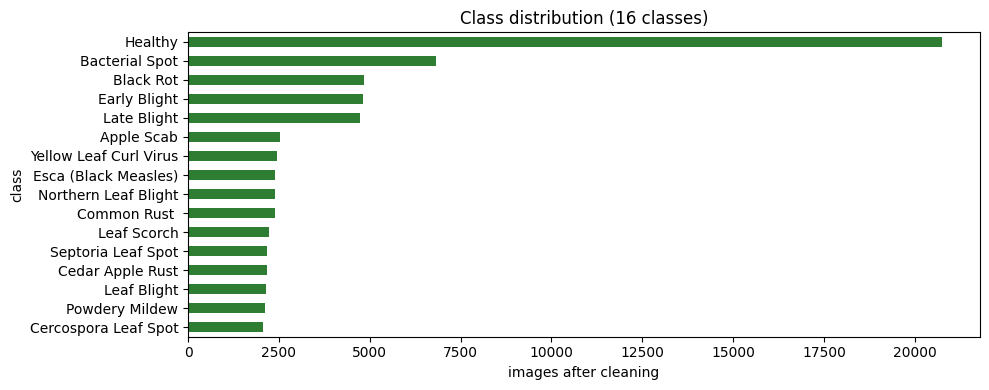


{
  "dataset": "archive (10).zip",
  "seed": 42,
  "raw_images": 67118,
  "rejected_integrity": 0,
  "removed_exact_duplicates": 33,
  "removed_near_duplicates": 97,
  "cross_class_duplicate_groups": 7,
  "dropped_rare_classes": [],
  "final_images": 66988,
  "final_classes": 16,
  "imbalance_ratio": 10.113,
  "retention_pct": 99.81
}


In [ ]:
# =====================================================================
# STEP 2c | CLASS DISTRIBUTION + CLEANING REPORT
# =====================================================================

counts = dedup_df["class"].value_counts()
rare = counts[counts < CFG.min_images_per_class]

if len(rare):
    print("dropping", len(rare), "class(es) under", CFG.min_images_per_class, "images:", list(rare.index))
    dedup_df = dedup_df[~dedup_df["class"].isin(rare.index)].reset_index(drop=True)
    counts = dedup_df["class"].value_counts()

print("classes:", len(counts), "| images:", format(len(dedup_df), ","))
print("imbalance ratio (max/min):", round(float(counts.max() / counts.min()), 2),
      " max =", counts.idxmax(), counts.max(), "| min =", counts.idxmin(), counts.min())

fig, ax = plt.subplots(figsize=(10, max(4, len(counts) * 0.22)))
counts.sort_values().plot.barh(ax=ax, color="#2e7d32")
ax.set_xlabel("images after cleaning")
ax.set_title("Class distribution (" + str(len(counts)) + " classes)")
plt.tight_layout()
plt.savefig(CFG.audit_root / "class_distribution.png", dpi=140)
plt.show()

report = {
    "dataset": DATASET,
    "seed": SEED,
    "raw_images": int(len(raw_df)),
    "rejected_integrity": int((~audit_df.ok).sum()),
    "removed_exact_duplicates": n_exact,
    "removed_near_duplicates": n_near,
    "cross_class_duplicate_groups": n_crossclass,
    "dropped_rare_classes": list(rare.index),
    "final_images": int(len(dedup_df)),
    "final_classes": int(counts.size),
    "imbalance_ratio": round(float(counts.max() / counts.min()), 3),
    "retention_pct": round(100 * len(dedup_df) / len(raw_df), 2),
}
(CFG.audit_root / "cleaning_report.json").write_text(json.dumps(report, indent=2))
print()
print(json.dumps(report, indent=2))

### Step 3 — Stratified split and materialisation

**Split: 80 / 10 / 10, stratified on the class label**, done on the *cleaned* index — so the test set can never contain a duplicate of a training image, which is the single most common cause of inflated PlantVillage accuracy.

**Stored at 256 px, not 224.** The architecture diagram says resize to 224; writing 224 to disk would force a *deterministic* resize and throw away the pixels that *RandomResizedCrop* needs. Storing the short side at 256 and cropping to 224 inside the transform keeps augmentation meaningful at train time and gives a clean deterministic center-crop at eval time.

Output layout, exactly as block 3 of the diagram:

    processed_dataset/
      train/ class_1/ ... class_N/
      val/   class_1/ ... class_N/
      test/  class_1/ ... class_N/



In [ ]:
# =====================================================================
# STEP 3 | STRATIFIED 80/10/10 SPLIT  ->  resize  ->  processed_dataset/
# =====================================================================

from sklearn.model_selection import train_test_split

idx_train, idx_tmp = train_test_split(
    dedup_df.index, test_size=CFG.val_frac + CFG.test_frac,
    stratify=dedup_df["class"], random_state=SEED)

rel_test = CFG.test_frac / (CFG.val_frac + CFG.test_frac)
idx_val, idx_test = train_test_split(
    idx_tmp, test_size=rel_test,
    stratify=dedup_df.loc[idx_tmp, "class"], random_state=SEED)

dedup_df["split"] = "train"
dedup_df.loc[idx_val, "split"] = "val"
dedup_df.loc[idx_test, "split"] = "test"
print(dedup_df["split"].value_counts().to_frame("images"))

classes = sorted(dedup_df["class"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}

if CFG.processed_root.exists():
    shutil.rmtree(CFG.processed_root)
for s in ("train", "val", "test"):
    for c in classes:
        (CFG.processed_root / s / c).mkdir(parents=True, exist_ok=True)


def materialize(rec):
    dst = CFG.processed_root / rec["split"] / rec["class"] / (rec["md5"][:12] + ".jpg")
    if dst.exists():
        return str(dst)
    try:
        with Image.open(rec["path"]) as im:
            im = im.convert("RGB").resize((CFG.store_size, CFG.store_size), Image.BICUBIC)
            im.save(dst, quality=CFG.jpeg_q, optimize=True)
        return str(dst)
    except Exception:
        return ""


recs = dedup_df.to_dict("records")
with ThreadPoolExecutor(max_workers=16) as ex:
    dedup_df["proc_path"] = list(tqdm(ex.map(materialize, recs),
                                      total=len(recs), desc="resize + save"))

failed = int((dedup_df.proc_path == "").sum())
manifest = dedup_df[dedup_df.proc_path != ""][
    ["proc_path", "path", "class", "split", "md5", "w", "h"]]
manifest.to_csv(CFG.audit_root / "03_manifest.csv", index=False)
(CFG.audit_root / "class_mapping.json").write_text(json.dumps(class_to_idx, indent=2))

print()
print("written:", format(len(manifest), ","), "| failed:", failed)
display(manifest.groupby(["class", "split"]).size().unstack("split")[["train", "val", "test"]].head(12))

       images
split        
train   53590
test     6699
val      6699


resize + save:   0%|          | 0/66988 [00:00<?, ?it/s]


written: 66,988 | failed: 0


split,train,val,test
class,,,
Apple Scab,2016,252,252
Bacterial Spot,5452,682,681
Black Rot,3875,485,484
Cedar Apple Rust,1742,218,218
Cercospora Leaf Spot,1642,205,205
Common Rust,1907,238,239
Early Blight,3859,482,483
Esca (Black Measles),1920,240,240
Healthy,16602,2075,2075


### Step 4 — Transforms, Dataset and DataLoader

**Augmentation is applied to the training split only** (block 2 of the diagram). Validation and test get a deterministic resize + center-crop, so the metrics measure the model, not the augmentation.

| | train | val / test |
|---|---|---|
| geometry | RandomResizedCrop(224, scale 0.7-1.0), H-flip, V-flip 0.2, rotation 20 deg | Resize(256) + CenterCrop(224) |
| photometric | ColorJitter(0.25 brightness/contrast/saturation, 0.03 hue), Gaussian blur p=0.2 | none |
| occlusion | RandomErasing p=0.15 | none |
| normalisation | ImageNet mean/std | ImageNet mean/std |

*Why these:* vertical flip and rotation are safe here because a leaf has no canonical "up"; colour jitter is kept mild because hue **is** disease signal on a leaf; blur and erasing stand in for out-of-focus and partially occluded field photos, which is where a lab-trained PlantVillage model usually breaks.

**ImageNet mean/std** rather than dataset statistics, because the backbone (ResNet34 / ResNet50 / MobileNetV2) was pre-trained under exactly that normalisation.

**WeightedRandomSampler** handles the class imbalance measured in Step 2c, so the minority disease classes are not drowned out — an alternative to class-weighted loss, and easier to reason about when reporting per-class recall.

In [ ]:
# =====================================================================
# STEP 4 | TRANSFORMS + DATASET + DATALOADER
# =====================================================================

from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import transforms, datasets

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(CFG.img_size, scale=(0.7, 1.0), ratio=(0.85, 1.18)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomApply([transforms.RandomRotation(20)], p=0.5),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.25, hue=0.03),
    transforms.RandomApply([transforms.GaussianBlur(3, (0.1, 1.5))], p=0.2),
    transforms.ToTensor(),
    transforms.Normalize(CFG.imagenet_mean, CFG.imagenet_std),
    transforms.RandomErasing(p=0.15, scale=(0.02, 0.10)),
])

eval_tf = transforms.Compose([
    transforms.Resize(CFG.store_size),
    transforms.CenterCrop(CFG.img_size),
    transforms.ToTensor(),
    transforms.Normalize(CFG.imagenet_mean, CFG.imagenet_std),
])

train_ds = datasets.ImageFolder(CFG.processed_root / "train", transform=train_tf)
val_ds   = datasets.ImageFolder(CFG.processed_root / "val",   transform=eval_tf)
test_ds  = datasets.ImageFolder(CFG.processed_root / "test",  transform=eval_tf)

assert train_ds.class_to_idx == val_ds.class_to_idx == test_ds.class_to_idx, "class index mismatch"
assert train_ds.class_to_idx == class_to_idx, "ImageFolder mapping differs from class_mapping.json"

# ---- class-balanced sampling for the training split -----------------
targets = np.array(train_ds.targets)
class_count = np.bincount(targets, minlength=len(train_ds.classes))
sample_w = 1.0 / class_count[targets]
sampler = WeightedRandomSampler(torch.DoubleTensor(sample_w), len(sample_w), replacement=True)

loader_kw = dict(num_workers=CFG.num_workers,
                 pin_memory=torch.cuda.is_available(),
                 persistent_workers=CFG.num_workers > 0)

train_loader = DataLoader(train_ds, batch_size=CFG.batch_size, sampler=sampler,
                          drop_last=True, **loader_kw)
val_loader   = DataLoader(val_ds,  batch_size=CFG.batch_size, shuffle=False, **loader_kw)
test_loader  = DataLoader(test_ds, batch_size=CFG.batch_size, shuffle=False, **loader_kw)

print("classes :", len(train_ds.classes))
print("train   :", format(len(train_ds), ","), "| val:", format(len(val_ds), ","),
      "| test:", format(len(test_ds), ","))
print("batches per epoch:", len(train_loader))

classes : 16
train   : 53,590 | val: 6,699 | test: 6,699
batches per epoch: 1674


batch tensor : (32, 3, 224, 224) torch.float32 | labels: (32,)
value range  : [ -2.12 , 2.64 ]  (expected about -2.1 .. 2.6 after ImageNet normalisation)
images present in more than one split: 0 (must be 0)


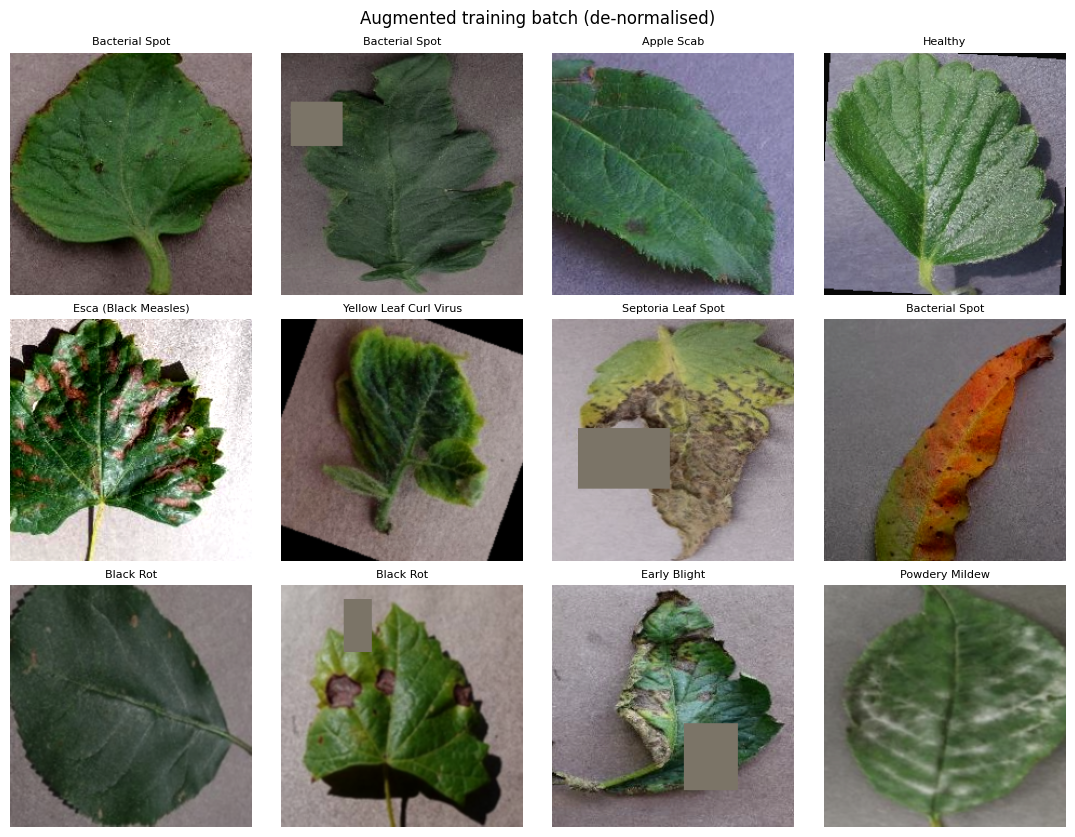


artefacts in /content/agri/audit
  - 00_raw_index.csv ( 7727.5 KB )
  - 01_integrity_audit.csv ( 9295.3 KB )
  - 02_exact_duplicates.csv ( 5.8 KB )
  - 02_near_duplicates.csv ( 17.5 KB )
  - 03_manifest.csv ( 15183.8 KB )
  - class_distribution.png ( 66.6 KB )
  - class_mapping.json ( 0.4 KB )
  - cleaning_report.json ( 0.3 KB )
  - sample_batch.png ( 1756.3 KB )


In [ ]:
# =====================================================================
# STEP 5 | SANITY CHECK  -  shapes, value range, leakage, visual grid
# =====================================================================

xb, yb = next(iter(train_loader))
print("batch tensor :", tuple(xb.shape), xb.dtype, "| labels:", tuple(yb.shape))
print("value range  : [", round(float(xb.min()), 2), ",", round(float(xb.max()), 2),
      "]  (expected about -2.1 .. 2.6 after ImageNet normalisation)")
assert tuple(xb.shape[1:]) == (3, CFG.img_size, CFG.img_size)

# ---- hard leakage check: no md5 may appear in two splits ------------
leak = manifest.groupby("md5")["split"].nunique()
print("images present in more than one split:", int((leak > 1).sum()), "(must be 0)")
assert int((leak > 1).sum()) == 0

# ---- visual check: de-normalise and plot ----------------------------
mean = torch.tensor(CFG.imagenet_mean).view(1, 3, 1, 1)
std  = torch.tensor(CFG.imagenet_std).view(1, 3, 1, 1)
grid = (xb[:12] * std + mean).clamp(0, 1).permute(0, 2, 3, 1).numpy()

fig, axes = plt.subplots(3, 4, figsize=(11, 8.5))
for ax, img, lab in zip(axes.ravel(), grid, yb[:12]):
    ax.imshow(img)
    ax.set_title(train_ds.classes[int(lab)][:30], fontsize=8)
    ax.axis("off")
plt.suptitle("Augmented training batch (de-normalised)")
plt.tight_layout()
plt.savefig(CFG.audit_root / "sample_batch.png", dpi=130)
plt.show()

print()
print("artefacts in", CFG.audit_root)
for f in sorted(CFG.audit_root.iterdir()):
    print("  -", f.name, "(", round(f.stat().st_size / 1024, 1), "KB )")

### Outputs of this notebook

| Artefact | What it is |
|---|---|
| processed_dataset/{train,val,test}/class_i/ | cleaned, de-duplicated, 256 px RGB images — block 3 of the architecture |
| train_loader / val_loader / test_loader | block 4, ready to hand to the transfer-learning model |
| audit/00_raw_index.csv | every image found in the archive |
| audit/01_integrity_audit.csv | per-image verdict with rejection reason, width, height, mode |
| audit/02_exact_duplicates.csv, 02_near_duplicates.csv | exactly which files were removed and why |
| audit/03_manifest.csv | final dataset: source path, class, split, hash |
| audit/class_mapping.json | class -> index, reused by the confusion matrix and the report |
| audit/cleaning_report.json | one-page summary of the whole cleaning run |
| audit/class_distribution.png, sample_batch.png | figures for the slides |

### To persist across sessions

Colab wipes /content on disconnect. Mount Drive and copy once the run is clean:

    from google.colab import drive
    drive.mount("/content/drive")
    !cp -r /content/agri/audit "/content/drive/MyDrive/agri_audit"
    !cd /content/agri && zip -qr "/content/drive/MyDrive/processed_dataset.zip" processed_dataset

### Next (blocks 5 to 8)

Model: pre-trained backbone + custom head · Stage 1 head-only warm-up, Stage 2 fine-tune upper layers · CrossEntropy, Adam, StepLR, early stopping on val loss, best-model checkpoint · accuracy / precision / recall / F1, confusion matrix, error analysis · Grad-CAM++ overlays for explainability.



In [ ]:
from google.colab import drive
drive.mount("/content/drive")
!cp -r /content/agri/audit "/content/drive/MyDrive/agri_audit"
!cd /content/agri && zip -qr "/content/drive/MyDrive/processed_dataset.zip" processed_dataset

Mounted at /content/drive
cp: cannot stat '/content/agri/audit': No such file or directory
/bin/bash: line 1: cd: /content/agri: No such file or directory


---

# Part 2 — Transfer learning: shared feature extractor, then per-backbone fine-tuning

Blocks 5 to 7 of the architecture. Part 1 ended with `processed_dataset/{train,val,test}` and a DataLoader; this half turns that into a ranked set of models.

The run is deliberately split into two stages, and every backbone goes through both of them under an identical recipe:

| | Stage 1 — frozen feature extraction | Stage 2 — fine-tuning |
|---|---|---|
| trunk | frozen, `requires_grad=False` | top blocks unfrozen, lower blocks still frozen |
| input | deterministic resize + center-crop, no augmentation | full augmentation policy from Part 1 |
| what trains | the classifier head only | head + top blocks, discriminative learning rates |
| cost | one forward pass per image, cached to disk, then seconds per epoch | full backward pass, minutes per epoch |
| what it measures | how linearly separable the 16 classes already are in ImageNet feature space | how much the backbone gains by adapting to leaf texture |

**The shared layer** is `FeatureExtractor`: it wraps any timm backbone so that all of them expose the same thing — a pooled `(B, feat_dim)` embedding — and nothing downstream (caching, head training, fine-tuning, benchmarking) ever branches on architecture. ResNet50, EfficientNet-B0, ConvNeXt-Tiny, MobileNetV3-Small and DeiT-Small are then swapped through that one interface.

Two things are deliberately *not* shared, because sharing them would invalidate the comparison:

- **Normalisation and crop ratio.** Each checkpoint was pre-trained under its own mean/std and `crop_pct`; these are read from `timm.data.resolve_model_data_config` per backbone. Forcing the ImageNet ResNet statistics onto DeiT would handicap it for no scientific reason.
- **Which blocks unfreeze.** A ResNet `layer4` and a DeiT `blocks.8-11` are not the same depth of the network. The unfreeze set is declared per backbone in the registry, so "fine-tune the top stage" means the same thing architecturally rather than the same string match.

Stage 1 also pays for itself twice: the head it trains is the warm start for Stage 2, so fine-tuning never begins with a random classifier pushing large meaningless gradients back into pre-trained weights.

**Compute plan.** Stage 2 ranks the five backbones on a stratified 25% slice of train for 5 epochs each, then the winner is retrained on 100% of train for up to 15 epochs. Ranking on the same slice with the same schedule is the honest comparison; the full run is only for the model you actually ship. Results are written to disk after each backbone, so a Colab disconnect costs one backbone, not the whole benchmark.

In [ ]:
# =====================================================================
# STEP 6a | PART-2 ENVIRONMENT + ATTACH TO processed_dataset
# =====================================================================
!pip -q install timm

import os, json, math, time, random, shutil, warnings
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset, WeightedRandomSampler
from torchvision import datasets, transforms
from tqdm.auto import tqdm

import timm
from timm.data import resolve_model_data_config

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             precision_recall_fscore_support,
                             confusion_matrix, classification_report)

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


class CFG2:
    # ---- paths ------------------------------------------------------
    work_root      = Path("/content/agri")
    processed_root = work_root / "processed_dataset"
    audit_root     = work_root / "audit"
    feat_root      = work_root / "features"       # cached frozen embeddings
    ckpt_root      = work_root / "checkpoints"

    # ---- loaders ----------------------------------------------------
    num_workers    = 2
    batch_size     = 48          # fine-tuning
    eval_bs        = 96          # inference / feature caching

    # ---- stage 1 : frozen features + head ---------------------------
    head_hidden    = 0           # 0 = linear probe, >0 = one hidden layer
    head_dropout   = 0.2
    probe_epochs   = 15
    probe_bs       = 1024
    probe_lr       = 3e-3
    probe_wd       = 1e-4

    # ---- stage 2 : fine-tuning benchmark ----------------------------
    bench_frac     = 0.25        # stratified slice of train used to rank backbones
    bench_epochs   = 5
    ft_backbone_lr = 1e-4        # discriminative LR - trunk learns 10x slower
    ft_head_lr     = 1e-3
    ft_wd          = 1e-4
    label_smooth   = 0.05
    warmup_frac    = 0.10
    patience       = 3           # early stopping on val macro-F1

    # ---- final run on the winning backbone --------------------------
    final_epochs   = 15

    amp            = torch.cuda.is_available()

for _p in (CFG2.feat_root, CFG2.ckpt_root, CFG2.audit_root):
    _p.mkdir(parents=True, exist_ok=True)

# ---- make sure the cleaned dataset is actually on disk --------------
# leave empty if Steps 0-5 ran in this same session; point it at the zip
# you saved to Drive to pick up in a fresh runtime
PROCESSED_ZIP = ""      # e.g. "/content/drive/MyDrive/processed_dataset.zip"

if not (CFG2.processed_root / "train").exists():
    if PROCESSED_ZIP and Path(PROCESSED_ZIP).exists():
        print("unpacking", PROCESSED_ZIP, "...")
        shutil.unpack_archive(PROCESSED_ZIP, CFG2.work_root)
    else:
        raise FileNotFoundError(
            "No processed_dataset at " + str(CFG2.processed_root) + ".\n"
            "Either re-run Steps 0-3 of Part 1, or set PROCESSED_ZIP to the zip "
            "you saved to Drive, e.g. /content/drive/MyDrive/processed_dataset.zip"
        )

CLASSES   = sorted(p.name for p in (CFG2.processed_root / "train").iterdir() if p.is_dir())
N_CLASSES = len(CLASSES)

# targets of the full training split, used for the stratified benchmark slice
_scan         = datasets.ImageFolder(CFG2.processed_root / "train")
TRAIN_TARGETS = np.array(_scan.targets)
assert _scan.classes == CLASSES

# cross-check against Part 1 if the mapping file survived
_map_file = CFG2.audit_root / "class_mapping.json"
if _map_file.exists():
    assert json.loads(_map_file.read_text()) == {c: i for i, c in enumerate(CLASSES)}, \
        "class order differs from Part 1 class_mapping.json"
    print("class mapping matches Part 1")

sizes = {s: sum(1 for _ in (CFG2.processed_root / s).rglob("*.jpg")) for s in ("train", "val", "test")}

print("device  :", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU only")
print("torch   :", torch.__version__, "| timm:", timm.__version__)
print("classes :", N_CLASSES)
print("images  :", sizes)
print("bench slice:", int(CFG2.bench_frac * sizes["train"]), "train images x", CFG2.bench_epochs, "epochs per backbone")

## Step 6b — The shared feature-extraction layer

Five backbones, one interface. `FeatureExtractor(spec)` builds the trunk with `num_classes=0`, so timm returns the pooled embedding instead of its own 1000-way classifier, and exposes:

- `.forward(x) -> (B, feat_dim)` — the shared contract every later stage depends on
- `.feat_dim` — 2048 / 1280 / 768 / 1024 / 384 depending on the trunk, measured with a dummy forward rather than read from `trunk.num_features`, because the two disagree: MobileNetV3-Small reports 576 and emits 1024
- `.data_cfg` — the mean, std, input size and crop ratio that checkpoint was trained under
- `.freeze()` / `.unfreeze_top()` — the stage-1 / stage-2 switch
- `.freeze_frozen_bn()` — explained below

`ClassifierHead` is the same for all of them: `BatchNorm1d -> Dropout -> Linear(feat_dim, 16)`, optionally with a hidden layer. The BatchNorm matters, because the five trunks emit features on very different scales and a shared learning rate would otherwise suit only one of them.

**Why `freeze_frozen_bn()`.** Freezing a BatchNorm layer's weights does not freeze its running mean and variance — those keep updating from every forward pass in `train()` mode. In a partially fine-tuned network that silently changes the frozen part of the trunk while you are training the top of it, and the usual symptom is a validation curve that drifts for no visible reason. The helper puts any BatchNorm whose parameters are all frozen back into `eval()` mode after each `model.train()` call. MobileNetV3, EfficientNet and ResNet all need this; DeiT uses LayerNorm and is unaffected.

**Unfreeze sets.** Declared per backbone rather than by a depth percentage, so "unfreeze the last stage" is architecturally the same decision in each case:

| backbone | trunk params unfrozen in stage 2 |
|---|---|
| ResNet50 | `layer4` |
| EfficientNet-B0 | `blocks.5`, `blocks.6`, `conv_head`, `bn2` |
| ConvNeXt-Tiny | `stages.3`, `norm_pre`, `head.` |
| MobileNetV3-Small | `blocks.4`, `blocks.5`, `conv_head` |
| DeiT-Small | `blocks.8` to `blocks.11`, `norm.` |

The last cell builds all five with random weights and prints the resulting shapes and trainable counts — a cheap check that every unfreeze key actually matches something before you spend GPU time.

In [ ]:
# =====================================================================
# STEP 6b | SHARED FEATURE EXTRACTOR + HEAD + LOADER FACTORY
# =====================================================================

@dataclass
class BackboneSpec:
    key:      str
    timm_id:  str
    unfreeze: tuple     # parameter-name fragments unfrozen in stage 2
    family:   str

BACKBONES = [
    BackboneSpec("resnet50",   "resnet50",
                 ("layer4",), "CNN residual"),
    BackboneSpec("effnet_b0",  "efficientnet_b0",
                 ("blocks.5", "blocks.6", "conv_head", "bn2"), "CNN compound-scaled"),
    BackboneSpec("convnext_t", "convnext_tiny",
                 ("stages.3", "norm_pre", "head."), "CNN modern"),
    BackboneSpec("mnetv3_s",   "mobilenetv3_small_100",
                 ("blocks.4", "blocks.5", "conv_head"), "CNN edge"),
    BackboneSpec("deit_s",     "deit_small_patch16_224",
                 ("blocks.8", "blocks.9", "blocks.10", "blocks.11", "norm."), "Transformer"),
]
SPEC = {b.key: b for b in BACKBONES}


class FeatureExtractor(nn.Module):
    """The shared layer. Wraps any timm backbone so every architecture
    exposes the same contract: an image batch in, a pooled (B, feat_dim)
    embedding out. Nothing downstream branches on the architecture."""

    def __init__(self, spec, pretrained=True):
        super().__init__()
        self.spec     = spec
        self.trunk    = timm.create_model(spec.timm_id, pretrained=pretrained, num_classes=0)
        self.data_cfg = resolve_model_data_config(self.trunk)
        self.feat_dim = self._measure_width()

    def _measure_width(self):
        """Measure the pooled output width with a dummy forward instead of
        trusting trunk.num_features: MobileNetV3-Small reports 576 there but
        actually emits 1024 with num_classes=0, which would silently build a
        head of the wrong width."""
        was_training = self.trunk.training
        self.trunk.eval()
        with torch.no_grad():
            z = self.trunk(torch.zeros(2, *tuple(self.data_cfg["input_size"])))
        self.trunk.train(was_training)
        assert z.ndim == 2, self.spec.timm_id + " did not return a pooled 2-D embedding"
        return int(z.shape[-1])

    def forward(self, x):
        return self.trunk(x)

    def freeze(self):
        for p in self.trunk.parameters():
            p.requires_grad_(False)
        return self

    def unfreeze_top(self):
        n = 0
        for name, p in self.trunk.named_parameters():
            if any(k in name for k in self.spec.unfreeze):
                p.requires_grad_(True)
                n += p.numel()
        if n == 0:
            raise RuntimeError("unfreeze keys matched no parameter in " + self.spec.timm_id)
        return n

    def freeze_frozen_bn(self):
        """A BatchNorm with frozen weights still updates its running stats in
        train() mode, which quietly moves the frozen part of the trunk.
        Put every fully-frozen BN back into eval()."""
        for m in self.trunk.modules():
            if isinstance(m, (nn.BatchNorm1d, nn.BatchNorm2d)):
                if not any(p.requires_grad for p in m.parameters(recurse=False)):
                    m.eval()


class ClassifierHead(nn.Module):
    """Shared head. BatchNorm first, because the five trunks emit features on
    very different scales and one learning rate has to suit all of them."""

    def __init__(self, in_dim, n_classes, hidden=0, p_drop=0.2):
        super().__init__()
        layers = [nn.BatchNorm1d(in_dim), nn.Dropout(p_drop)]
        if hidden:
            layers += [nn.Linear(in_dim, hidden), nn.BatchNorm1d(hidden),
                       nn.GELU(), nn.Dropout(p_drop)]
            in_dim = hidden
        layers += [nn.Linear(in_dim, n_classes)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class TransferModel(nn.Module):
    def __init__(self, extractor, head):
        super().__init__()
        self.extractor = extractor
        self.head      = head

    def forward(self, x):
        return self.head(self.extractor(x))


# ---------------------------------------------------------------------
# per-backbone transforms: same augmentation policy as Part 1, but the
# normalisation and crop ratio each checkpoint was pre-trained under
# ---------------------------------------------------------------------
def make_transforms(data_cfg):
    mean = tuple(data_cfg["mean"])
    std  = tuple(data_cfg["std"])
    size = int(data_cfg["input_size"][-1])
    crop = float(data_cfg.get("crop_pct", 0.875))
    resize = int(round(size / crop))

    train_tf = transforms.Compose([
        transforms.RandomResizedCrop(size, scale=(0.7, 1.0), ratio=(0.85, 1.18)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.2),
        transforms.RandomApply([transforms.RandomRotation(20)], p=0.5),
        transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.25, hue=0.03),
        transforms.RandomApply([transforms.GaussianBlur(3, (0.1, 1.5))], p=0.2),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
        transforms.RandomErasing(p=0.15, scale=(0.02, 0.10)),
    ])
    eval_tf = transforms.Compose([
        transforms.Resize(resize),
        transforms.CenterCrop(size),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
    return train_tf, eval_tf


def stratified_subset(targets, frac, seed=SEED):
    """Class-proportional slice of the training split. None means use all."""
    if frac is None or frac >= 1.0:
        return None
    idx, _ = train_test_split(np.arange(len(targets)), train_size=frac,
                              stratify=targets, random_state=seed)
    return np.sort(idx)


def make_loaders(data_cfg, train_idx=None, augment=True, balanced=True):
    """train / val / test loaders for one backbone.

    augment=False + balanced=False gives the deterministic, in-order pass used
    for feature caching; the defaults give the stage-2 training setup."""
    train_tf, eval_tf = make_transforms(data_cfg)

    tr_full = datasets.ImageFolder(CFG2.processed_root / "train",
                                   transform=train_tf if augment else eval_tf)
    va      = datasets.ImageFolder(CFG2.processed_root / "val",  transform=eval_tf)
    te      = datasets.ImageFolder(CFG2.processed_root / "test", transform=eval_tf)
    assert tr_full.classes == va.classes == te.classes == CLASSES

    targets = np.array(tr_full.targets)
    if train_idx is None:
        tr_ds = tr_full
    else:
        tr_ds   = Subset(tr_full, list(train_idx))
        targets = targets[train_idx]

    kw = dict(num_workers=CFG2.num_workers,
              pin_memory=(DEVICE == "cuda"),
              persistent_workers=CFG2.num_workers > 0)

    if balanced:
        # same imbalance correction as Part 1: resample rather than reweight the
        # loss, so per-class recall stays easy to read
        cnt = np.bincount(targets, minlength=N_CLASSES)
        w   = 1.0 / np.maximum(cnt, 1)[targets]
        sampler = WeightedRandomSampler(torch.DoubleTensor(w), len(w), replacement=True)
        train_loader = DataLoader(tr_ds, batch_size=CFG2.batch_size, sampler=sampler,
                                  drop_last=True, **kw)
    else:
        train_loader = DataLoader(tr_ds, batch_size=CFG2.eval_bs, shuffle=False, **kw)

    val_loader  = DataLoader(va, batch_size=CFG2.eval_bs, shuffle=False, **kw)
    test_loader = DataLoader(te, batch_size=CFG2.eval_bs, shuffle=False, **kw)
    return train_loader, val_loader, test_loader, targets


def score(y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro",
                                                  zero_division=0)
    return {"acc":      float(accuracy_score(y_true, y_pred)),
            "bal_acc":  float(balanced_accuracy_score(y_true, y_pred)),
            "macro_p":  float(p),
            "macro_r":  float(r),
            "macro_f1": float(f1)}


# ---- sanity check: build all five with random weights ---------------
rows = []
for s in BACKBONES:
    ex = FeatureExtractor(s, pretrained=False)
    ex.freeze()
    n_un = ex.unfreeze_top()
    total = sum(p.numel() for p in ex.trunk.parameters())
    rows.append({"backbone": s.key, "timm_id": s.timm_id, "family": s.family,
                 "feat_dim": ex.feat_dim,
                 "params_M": round(total / 1e6, 2),
                 "unfrozen_M": round(n_un / 1e6, 2),
                 "unfrozen_%": round(100 * n_un / total, 1),
                 "input": ex.data_cfg["input_size"][-1],
                 "crop_pct": ex.data_cfg.get("crop_pct"),
                 "mean": tuple(round(float(v), 3) for v in ex.data_cfg["mean"])})
    del ex

display(pd.DataFrame(rows).set_index("backbone"))
print("all unfreeze keys matched - registry is consistent with the installed timm")

## Step 7 — Stage 1: frozen feature extraction and the linear probe

For each backbone the frozen trunk makes exactly one deterministic pass over all three splits, and the pooled embeddings are written to `features/<backbone>_<split>.pt` as float16. 67k images at 2048 dims is about 270 MB for ResNet50 and less for the others, so the whole cache fits comfortably in `/content`.

Once cached, training the head costs no image decoding and no convolution at all — 15 epochs over the full 53k training set take seconds, which is why it is worth doing properly rather than treating it as a warm-up.

Three reasons this stage exists rather than going straight to fine-tuning:

1. **It is the honest baseline.** The probe measures how much of the 16-way separation is already present in ImageNet features. If a frozen ConvNeXt-Tiny gets 0.94 macro-F1 and fine-tuning takes it to 0.96, the fine-tuning is worth two points, not the whole result — and that is the number that belongs in the paper.
2. **It warm-starts Stage 2.** The trained head is loaded into the fine-tuning model, so the first optimiser steps do not push large random-classifier gradients back into pre-trained weights. This is what the two-stage protocol in the architecture diagram is actually for.
3. **It is a cheap failure detector.** A probe that lands near chance means something upstream is wrong — wrong normalisation, scrambled labels, a dead split — and you find out in two minutes instead of two hours.

Augmentation is deliberately off here: the features have to be deterministic to be cacheable, and the probe is measuring the representation, not the augmentation policy. Class imbalance is handled with a weighted cross-entropy rather than a sampler, since at this stage the data is already a tensor in memory.

Set `FORCE_RECACHE = True` to recompute embeddings after changing anything about the transforms or the dataset.

In [ ]:
# =====================================================================
# STEP 7 | STAGE 1 - CACHE FROZEN EMBEDDINGS, TRAIN THE HEAD
# =====================================================================
FORCE_RECACHE = False

@torch.no_grad()
def cache_features(spec, force=False):
    """One deterministic forward pass per split with the trunk frozen."""
    out = {s: CFG2.feat_root / (spec.key + "_" + s + ".pt") for s in ("train", "val", "test")}
    if all(p.exists() for p in out.values()) and not force:
        print("  cached embeddings found, skipping extraction")
        return out

    ex = FeatureExtractor(spec).freeze().to(DEVICE).eval()
    tr_l, va_l, te_l, _ = make_loaders(ex.data_cfg, augment=False, balanced=False)

    for split, loader in (("train", tr_l), ("val", va_l), ("test", te_l)):
        feats, labs = [], []
        for xb, yb in tqdm(loader, desc="  " + spec.key + " / " + split, leave=False):
            with torch.amp.autocast("cuda", enabled=CFG2.amp):
                f = ex(xb.to(DEVICE, non_blocking=True))
            feats.append(f.float().cpu().to(torch.float16))
            labs.append(yb)
        torch.save({"f": torch.cat(feats), "y": torch.cat(labs), "dim": ex.feat_dim}, out[split])

    del ex
    torch.cuda.empty_cache()
    mb = sum(p.stat().st_size for p in out.values()) / 1e6
    print("  embeddings cached (" + str(round(mb, 1)) + " MB)")
    return out


def train_probe(spec, paths):
    """Train the shared head on cached frozen features. Returns metrics and
    the head state_dict, which becomes the warm start for stage 2."""
    data = {s: torch.load(paths[s]) for s in ("train", "val", "test")}
    dim  = int(data["train"]["dim"])

    X = {s: data[s]["f"].to(DEVICE) for s in data}          # float16 on GPU
    Y = {s: data[s]["y"].to(DEVICE) for s in data}

    head = ClassifierHead(dim, N_CLASSES, CFG2.head_hidden, CFG2.head_dropout).to(DEVICE)
    cnt  = torch.bincount(Y["train"], minlength=N_CLASSES).float()
    w    = (cnt.sum() / (N_CLASSES * cnt.clamp(min=1))).to(DEVICE)
    crit = nn.CrossEntropyLoss(weight=w, label_smoothing=CFG2.label_smooth)
    opt  = torch.optim.AdamW(head.parameters(), lr=CFG2.probe_lr, weight_decay=CFG2.probe_wd)
    sch  = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG2.probe_epochs)

    @torch.no_grad()
    def predict(split):
        head.eval()
        preds = []
        for i in range(0, len(X[split]), 4096):
            preds.append(head(X[split][i:i + 4096].float()).argmax(1))
        return torch.cat(preds).cpu().numpy(), Y[split].cpu().numpy()

    n, best_f1, best_state, t0 = len(X["train"]), -1.0, None, time.time()
    for ep in range(CFG2.probe_epochs):
        head.train()
        perm = torch.randperm(n, device=DEVICE)
        tot = 0.0
        for i in range(0, n, CFG2.probe_bs):
            b = perm[i:i + CFG2.probe_bs]
            if len(b) < 2:
                continue
            opt.zero_grad(set_to_none=True)
            loss = crit(head(X["train"][b].float()), Y["train"][b])
            loss.backward(); opt.step()
            tot += float(loss) * len(b)
        sch.step()
        vp, vy = predict("val")
        f1 = score(vy, vp)["macro_f1"]
        if f1 > best_f1:
            best_f1 = f1
            best_state = {k: v.detach().clone() for k, v in head.state_dict().items()}
        if ep == 0 or (ep + 1) % 5 == 0 or ep == CFG2.probe_epochs - 1:
            print("    epoch " + str(ep + 1).rjust(2) + "/" + str(CFG2.probe_epochs) +
                  "  loss " + format(tot / n, ".4f") + "  val macro-F1 " + format(f1, ".4f"))

    head.load_state_dict(best_state)
    vp, vy = predict("val")
    tp, ty = predict("test")
    val_m, test_m = score(vy, vp), score(ty, tp)
    secs = time.time() - t0

    for s in list(X):
        del X[s], Y[s]
    torch.cuda.empty_cache()

    return {"probe_val": val_m, "probe_test": test_m,
            "probe_secs": round(secs, 1), "feat_dim": dim}, best_state


# ---- run stage 1 for every backbone ---------------------------------
PROBE_HEADS   = {}
PROBE_METRICS = {}
probe_rows    = []

for spec in BACKBONES:
    print("[" + spec.key + "]")
    paths = cache_features(spec, force=FORCE_RECACHE)
    metrics, head_state = train_probe(spec, paths)
    torch.save(head_state, CFG2.ckpt_root / ("probe_head_" + spec.key + ".pt"))
    PROBE_HEADS[spec.key] = head_state
    probe_rows.append({"backbone": spec.key, "feat_dim": metrics["feat_dim"],
                       "probe_val_f1":  round(metrics["probe_val"]["macro_f1"], 4),
                       "probe_test_f1": round(metrics["probe_test"]["macro_f1"], 4),
                       "probe_test_acc": round(metrics["probe_test"]["acc"], 4),
                       "secs": metrics["probe_secs"]})
    PROBE_METRICS[spec.key] = metrics
    print("  frozen-feature test macro-F1:", round(metrics["probe_test"]["macro_f1"], 4), "\n")

probe_df = pd.DataFrame(probe_rows).set_index("backbone")
probe_df.to_csv(CFG2.audit_root / "10_linear_probe.csv")
display(probe_df)

## Step 8 — Stage 2: fine-tuning each backbone

Now the trunk moves. For each backbone: freeze everything, unfreeze the declared top blocks, load the Stage-1 head, and train end to end on the augmented data.

**Discriminative learning rates.** The head starts at `1e-3`, the unfrozen trunk at `1e-4`. The head is warm but still the newest part of the network; the trunk holds pre-trained features that a large learning rate would destroy faster than 5 epochs can rebuild. One optimiser, two parameter groups.

**Schedule.** 10% linear warm-up then cosine decay over the full run. The warm-up matters most for DeiT, where a cold large step into attention weights is the usual cause of a loss spike in the first few hundred iterations.

**Mixed precision and gradient clipping.** AMP roughly halves memory and gives about a 2x speed-up on a T4, which is what makes a five-backbone benchmark feasible in one session. Gradients are clipped at norm 1.0 after unscaling — cheap insurance against a single bad batch, again mostly for the transformer.

**Early stopping on validation macro-F1**, not accuracy and not loss. The classes are imbalanced, so accuracy is dominated by the large ones; macro-F1 is the metric the model should actually be selected on. Patience 3, best checkpoint kept.

**Imbalance** is handled by the `WeightedRandomSampler` from Part 1 rather than a class-weighted loss. Doing both would correct the same thing twice and quietly over-weight the rare classes.

Everything is written to `11_benchmark.json` as each backbone finishes, and backbones already present are skipped — so if Colab drops the connection halfway through, re-running this cell resumes rather than restarting. Set `FORCE_RERUN = True` to override.

Throughput is measured separately on synthetic batches so it reflects the model rather than the disk.

In [ ]:
# =====================================================================
# STEP 8 | STAGE 2 - FINE-TUNE EACH BACKBONE, RESUME-SAFE
# =====================================================================
FORCE_RERUN = False

def evaluate(model, loader, crit=None):
    model.eval()
    ys, ps, tot, n = [], [], 0.0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE, non_blocking=True)
            yd = yb.to(DEVICE, non_blocking=True)
            with torch.amp.autocast("cuda", enabled=CFG2.amp):
                out = model(xb)
                if crit is not None:
                    tot += float(crit(out, yd)) * len(yb); n += len(yb)
            ps.append(out.argmax(1).cpu()); ys.append(yb)
    y = torch.cat(ys).numpy(); p = torch.cat(ps).numpy()
    m = score(y, p); m["loss"] = tot / max(n, 1)
    return m, y, p


@torch.no_grad()
def measure_throughput(model, size, bs=64, iters=20):
    """Images/s on synthetic batches, so the number reflects the model and
    not the dataloader or the disk."""
    if DEVICE != "cuda":
        return float("nan")
    model.eval()
    x = torch.randn(bs, 3, size, size, device=DEVICE)
    for _ in range(5):
        with torch.amp.autocast("cuda", enabled=CFG2.amp):
            model(x)
    torch.cuda.synchronize(); t0 = time.time()
    for _ in range(iters):
        with torch.amp.autocast("cuda", enabled=CFG2.amp):
            model(x)
    torch.cuda.synchronize()
    return round(bs * iters / (time.time() - t0), 1)


def finetune(spec, train_idx, epochs, tag, warm_head=None, verbose=True):
    ex = FeatureExtractor(spec).freeze()
    n_unfrozen = ex.unfreeze_top()
    head = ClassifierHead(ex.feat_dim, N_CLASSES, CFG2.head_hidden, CFG2.head_dropout)
    if warm_head is not None:
        head.load_state_dict(warm_head)
    model = TransferModel(ex, head).to(DEVICE)

    tr_l, va_l, te_l, _ = make_loaders(ex.data_cfg, train_idx, augment=True, balanced=True)

    trunk_params = [p for p in ex.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(
        [{"params": trunk_params,        "lr": CFG2.ft_backbone_lr},
         {"params": head.parameters(),   "lr": CFG2.ft_head_lr}],
        weight_decay=CFG2.ft_wd)

    total_steps = max(1, epochs * len(tr_l))
    warm_steps  = max(1, int(CFG2.warmup_frac * total_steps))

    def lr_lambda(step):
        if step < warm_steps:
            return (step + 1) / warm_steps
        prog = (step - warm_steps) / max(1, total_steps - warm_steps)
        return 0.5 * (1.0 + math.cos(math.pi * min(prog, 1.0)))

    sch    = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
    crit   = nn.CrossEntropyLoss(label_smoothing=CFG2.label_smooth)
    scaler = torch.amp.GradScaler("cuda", enabled=CFG2.amp)
    ckpt   = CFG2.ckpt_root / (tag + "_" + spec.key + ".pt")

    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    best_f1, bad, history, t_start = -1.0, 0, [], time.time()

    for ep in range(epochs):
        model.train()
        ex.freeze_frozen_bn()
        run, seen, t0 = 0.0, 0, time.time()
        bar = tqdm(tr_l, desc="  " + spec.key + " ep " + str(ep + 1) + "/" + str(epochs),
                   leave=False)
        for xb, yb in bar:
            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=CFG2.amp):
                loss = crit(model(xb), yb)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(
                [p for g in opt.param_groups for p in g["params"]], 1.0)
            scaler.step(opt); scaler.update(); sch.step()
            run += float(loss) * len(yb); seen += len(yb)
            bar.set_postfix(loss=round(run / max(seen, 1), 4))

        vm, _, _ = evaluate(model, va_l, crit)
        ep_secs  = time.time() - t0
        history.append({"epoch": ep + 1, "train_loss": round(run / max(seen, 1), 4),
                        "val_loss": round(vm["loss"], 4),
                        "val_acc": round(vm["acc"], 4),
                        "val_macro_f1": round(vm["macro_f1"], 4),
                        "secs": round(ep_secs, 1)})
        if verbose:
            print("  ep " + str(ep + 1).rjust(2) + "/" + str(epochs) +
                  "  train " + format(run / max(seen, 1), ".4f") +
                  "  val " + format(vm["loss"], ".4f") +
                  "  val acc " + format(vm["acc"], ".4f") +
                  "  val macro-F1 " + format(vm["macro_f1"], ".4f") +
                  "  (" + str(round(ep_secs)) + "s)")

        if vm["macro_f1"] > best_f1:
            best_f1, bad = vm["macro_f1"], 0
            torch.save({"extractor": ex.state_dict(), "head": head.state_dict(),
                        "spec": spec.key, "epoch": ep + 1,
                        "val_macro_f1": best_f1, "classes": CLASSES}, ckpt)
        else:
            bad += 1
            if bad >= CFG2.patience:
                print("  early stop at epoch", ep + 1)
                break

    # ---- best checkpoint, then test -----------------------------------
    state = torch.load(ckpt, map_location=DEVICE, weights_only=True)
    ex.load_state_dict(state["extractor"]); head.load_state_dict(state["head"])
    test_m, y_true, y_pred = evaluate(model, te_l, crit)
    size  = int(ex.data_cfg["input_size"][-1])
    thr   = measure_throughput(model, size)
    peak  = round(torch.cuda.max_memory_allocated() / 1e9, 2) if DEVICE == "cuda" else None

    out = {"backbone": spec.key, "timm_id": spec.timm_id, "family": spec.family,
           "feat_dim": ex.feat_dim,
           "params_M": round(sum(p.numel() for p in ex.trunk.parameters()) / 1e6, 2),
           "trainable_M": round(n_unfrozen / 1e6, 2),
           "epochs_run": len(history), "best_epoch": int(state["epoch"]),
           "ft_val_f1": round(float(best_f1), 4),
           "ft_test_acc": round(test_m["acc"], 4),
           "ft_test_bal_acc": round(test_m["bal_acc"], 4),
           "ft_test_f1": round(test_m["macro_f1"], 4),
           "ft_test_p": round(test_m["macro_p"], 4),
           "ft_test_r": round(test_m["macro_r"], 4),
           "img_per_s": thr, "peak_gpu_GB": peak,
           "train_min": round((time.time() - t_start) / 60, 1),
           "sec_per_epoch": round(np.mean([h["secs"] for h in history]), 1),
           "history": history, "ckpt": str(ckpt)}

    del model, ex, head, opt, tr_l, va_l, te_l
    torch.cuda.empty_cache()
    return out, y_true, y_pred


# ---- benchmark loop, resumable --------------------------------------
RESULTS_PATH = CFG2.audit_root / "11_benchmark.json"
results   = json.loads(RESULTS_PATH.read_text()) if RESULTS_PATH.exists() else {}
bench_idx = stratified_subset(TRAIN_TARGETS, CFG2.bench_frac)
print("benchmark slice:", len(bench_idx) if bench_idx is not None else len(TRAIN_TARGETS),
      "train images |", CFG2.bench_epochs, "epochs per backbone\n")

for spec in BACKBONES:
    if spec.key in results and not FORCE_RERUN:
        print("[" + spec.key + "] already benchmarked, skipping")
        continue
    print("[" + spec.key + "]  " + spec.timm_id)

    warm = PROBE_HEADS.get(spec.key)
    if warm is None:
        pf = CFG2.ckpt_root / ("probe_head_" + spec.key + ".pt")
        warm = torch.load(pf, map_location="cpu", weights_only=True) if pf.exists() else None

    res, _, _ = finetune(spec, bench_idx, CFG2.bench_epochs, "bench", warm_head=warm)

    pm = PROBE_METRICS.get(spec.key)
    if pm:
        res["probe_val_f1"]   = round(pm["probe_val"]["macro_f1"], 4)
        res["probe_test_f1"]  = round(pm["probe_test"]["macro_f1"], 4)
        res["probe_test_acc"] = round(pm["probe_test"]["acc"], 4)

    results[spec.key] = res
    RESULTS_PATH.write_text(json.dumps(results, indent=2))
    print("  test macro-F1 " + format(res["ft_test_f1"], ".4f") +
          " | acc " + format(res["ft_test_acc"], ".4f") +
          " | " + str(res["train_min"]) + " min\n")

print("benchmark written to", RESULTS_PATH)

## Step 9 — Benchmark

The table every later claim rests on. Columns worth reading as a pair:

- `probe_test_f1` vs `ft_test_f1` — frozen ImageNet features vs an adapted trunk. The difference, shown as `lift`, is what the fine-tuning stage bought. On PlantVillage the probe is usually already strong, so a small lift is the expected result, not a failed experiment.
- `params_M` vs `trainable_M` — how much of each network stage 2 actually moved.
- `img_per_s` and `peak_gpu_GB` — the deployment axis. If this is ever going to run on a field device under TIH-IoT, a backbone that is two points behind at eight times the throughput is the better choice, and the table should say so rather than reporting accuracy alone.

All five were trained on the same slice, the same schedule and the same seed, so the comparison is fair in the one way that matters.

In [ ]:
# =====================================================================
# STEP 9 | BENCHMARK TABLE + FIGURES
# =====================================================================
rows = []
for k, r in results.items():
    row = {k2: v for k2, v in r.items() if k2 not in ("history", "ckpt", "timm_id")}
    if "probe_test_f1" in r:
        row["lift"] = round(r["ft_test_f1"] - r["probe_test_f1"], 4)
    rows.append(row)

cols = ["backbone", "family", "params_M", "trainable_M", "feat_dim",
        "probe_test_f1", "ft_test_f1", "lift", "ft_test_acc", "ft_test_bal_acc",
        "ft_test_p", "ft_test_r", "ft_val_f1",
        "img_per_s", "peak_gpu_GB", "sec_per_epoch", "train_min",
        "best_epoch", "epochs_run"]
bench = pd.DataFrame(rows)
bench = bench[[c for c in cols if c in bench.columns]]
bench = bench.sort_values("ft_test_f1", ascending=False).reset_index(drop=True)
bench.to_csv(CFG2.audit_root / "11_benchmark.csv", index=False)
display(bench)

# ---- frozen vs fine-tuned -------------------------------------------
if "probe_test_f1" in bench.columns:
    b = bench.sort_values("ft_test_f1")
    y = np.arange(len(b)); h = 0.38
    fig, ax = plt.subplots(figsize=(9, max(3.5, 0.9 * len(b))))
    ax.barh(y - h / 2, b["probe_test_f1"], h, label="stage 1 - frozen features", color="#90a4ae")
    ax.barh(y + h / 2, b["ft_test_f1"],    h, label="stage 2 - fine-tuned",      color="#2e7d32")
    ax.set_yticks(y); ax.set_yticklabels(b["backbone"])
    ax.set_xlabel("test macro-F1"); ax.set_xlim(0, 1.02)
    ax.set_title("Frozen feature extraction vs fine-tuning (" + str(N_CLASSES) + " classes)")
    for yi, (p_, f_) in enumerate(zip(b["probe_test_f1"], b["ft_test_f1"])):
        ax.text(p_ + 0.005, yi - h / 2, format(p_, ".3f"), va="center", fontsize=8)
        ax.text(f_ + 0.005, yi + h / 2, format(f_, ".3f"), va="center", fontsize=8)
    ax.legend(loc="lower right"); plt.tight_layout()
    plt.savefig(CFG2.audit_root / "benchmark_probe_vs_finetune.png", dpi=140)
    plt.show()

# ---- accuracy vs cost -----------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5.5))
sc = ax.scatter(bench["params_M"], bench["ft_test_f1"],
                s=np.clip(bench["img_per_s"].fillna(100), 20, 1500) / 3 + 40,
                c="#2e7d32", alpha=0.65, edgecolor="black", linewidth=0.6)
for _, r in bench.iterrows():
    ax.annotate(r["backbone"], (r["params_M"], r["ft_test_f1"]),
                textcoords="offset points", xytext=(8, 6), fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("backbone parameters (M, log scale)")
ax.set_ylabel("test macro-F1")
ax.set_title("Accuracy vs model size - marker area is inference throughput")
ax.grid(alpha=0.25); plt.tight_layout()
plt.savefig(CFG2.audit_root / "benchmark_accuracy_vs_size.png", dpi=140)
plt.show()

# ---- validation curves ----------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))
for k, r in results.items():
    h = pd.DataFrame(r["history"])
    ax.plot(h["epoch"], h["val_macro_f1"], marker="o", ms=4, label=k)
ax.set_xlabel("epoch"); ax.set_ylabel("validation macro-F1")
ax.set_title("Stage 2 fine-tuning, " + str(int(CFG2.bench_frac * 100)) + "% train slice")
ax.grid(alpha=0.25); ax.legend(); plt.tight_layout()
plt.savefig(CFG2.audit_root / "benchmark_val_curves.png", dpi=140)
plt.show()

WINNER = bench.iloc[int(np.argmax(bench["ft_val_f1"].values))]["backbone"]
print("selected on validation macro-F1:", WINNER)

## Step 10 — Final model: winner retrained on the full training set

The benchmark ranked the backbones on a 25% slice; this retrains the winner on all of train for up to 15 epochs, same recipe, same early stopping. The selection used validation macro-F1 — the test split is touched once, here, for the number that goes in the report.

Outputs: the best checkpoint, the per-class precision/recall/F1 table, a row-normalised confusion matrix, and `12_final_report.json` with every hyperparameter the run used.

Budget roughly 7 minutes an epoch on a T4 for a ResNet50-sized trunk on 53k images. If the session is at risk of timing out, drop `CFG2.final_epochs` to 8 — early stopping usually fires before 12 anyway.

The confusion matrix here is also the input to block 8: the class pairs it confuses are the ones worth putting a Grad-CAM++ overlay on.

In [ ]:
# =====================================================================
# STEP 10 | RETRAIN THE WINNER ON 100% OF TRAIN, THEN TEST
# =====================================================================
spec = SPEC[WINNER]
print("final run:", spec.key, "(" + spec.timm_id + ") on", len(TRAIN_TARGETS),
      "train images,", CFG2.final_epochs, "epochs max\n")

warm = PROBE_HEADS.get(spec.key)
if warm is None:
    pf = CFG2.ckpt_root / ("probe_head_" + spec.key + ".pt")
    warm = torch.load(pf, map_location="cpu", weights_only=True) if pf.exists() else None

final_res, y_true, y_pred = finetune(spec, None, CFG2.final_epochs, "final", warm_head=warm)

print("\nTEST  accuracy " + format(final_res["ft_test_acc"], ".4f") +
      " | balanced acc " + format(final_res["ft_test_bal_acc"], ".4f") +
      " | macro-F1 " + format(final_res["ft_test_f1"], ".4f"))

# ---- per-class table ------------------------------------------------
rep = classification_report(y_true, y_pred, target_names=CLASSES,
                            output_dict=True, zero_division=0)
per_class = (pd.DataFrame(rep).T.loc[CLASSES]
             .rename(columns={"precision": "P", "recall": "R", "f1-score": "F1"}))
per_class["support"] = per_class["support"].astype(int)
per_class = per_class.round(4).sort_values("F1")
per_class.to_csv(CFG2.audit_root / "12_per_class_test.csv")
display(per_class)

# ---- confusion matrix -----------------------------------------------
cm   = confusion_matrix(y_true, y_pred, labels=range(N_CLASSES))
cmn  = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(max(7, 0.55 * N_CLASSES), max(6, 0.5 * N_CLASSES)))
im = ax.imshow(cmn, cmap="Greens", vmin=0, vmax=1)
ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
ax.set_xticklabels([c[:26] for c in CLASSES], rotation=90, fontsize=7)
ax.set_yticklabels([c[:26] for c in CLASSES], fontsize=7)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title(spec.key + " - row-normalised confusion matrix (test)")
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        if cmn[i, j] >= 0.01:
            ax.text(j, i, format(cmn[i, j], ".2f"), ha="center", va="center",
                    fontsize=6, color="white" if cmn[i, j] > 0.55 else "black")
fig.colorbar(im, ax=ax, fraction=0.045)
plt.tight_layout()
plt.savefig(CFG2.audit_root / "final_confusion_matrix.png", dpi=150)
plt.show()

# ---- the pairs worth a Grad-CAM++ look ------------------------------
off = cmn.copy(); np.fill_diagonal(off, 0)
pairs = [{"true": CLASSES[i], "predicted": CLASSES[j], "rate": round(float(off[i, j]), 4),
          "n": int(cm[i, j])}
         for i, j in zip(*np.unravel_index(np.argsort(off, axis=None)[::-1][:10], off.shape))
         if off[i, j] > 0]
print("\ntop confusions (block 8 should explain these):")
display(pd.DataFrame(pairs))

# ---- one JSON that reproduces the run -------------------------------
final_report = {
    "winner": spec.key, "timm_id": spec.timm_id,
    "selected_on": "validation macro-F1 over " + str(len(BACKBONES)) + " backbones",
    "classes": CLASSES, "n_classes": N_CLASSES, "seed": SEED,
    "images": sizes,
    "stage1": {"epochs": CFG2.probe_epochs, "lr": CFG2.probe_lr, "wd": CFG2.probe_wd,
               "head_hidden": CFG2.head_hidden, "augmentation": False,
               "test_macro_f1": results[spec.key].get("probe_test_f1")},
    "stage2": {"epochs_max": CFG2.final_epochs, "epochs_run": final_res["epochs_run"],
               "best_epoch": final_res["best_epoch"],
               "backbone_lr": CFG2.ft_backbone_lr, "head_lr": CFG2.ft_head_lr,
               "wd": CFG2.ft_wd, "label_smoothing": CFG2.label_smooth,
               "warmup_frac": CFG2.warmup_frac, "batch_size": CFG2.batch_size,
               "amp": CFG2.amp, "unfrozen_params_M": final_res["trainable_M"],
               "unfreeze_keys": list(spec.unfreeze)},
    "test": {"accuracy": final_res["ft_test_acc"],
             "balanced_accuracy": final_res["ft_test_bal_acc"],
             "macro_precision": final_res["ft_test_p"],
             "macro_recall": final_res["ft_test_r"],
             "macro_f1": final_res["ft_test_f1"]},
    "throughput_img_per_s": final_res["img_per_s"],
    "peak_gpu_GB": final_res["peak_gpu_GB"],
    "train_minutes": final_res["train_min"],
    "checkpoint": final_res["ckpt"],
    "top_confusions": pairs,
    "history": final_res["history"],
}
(CFG2.audit_root / "12_final_report.json").write_text(json.dumps(final_report, indent=2))
print("\nwritten:", CFG2.audit_root / "12_final_report.json")
print("checkpoint:", final_res["ckpt"])

In [ ]:
# =====================================================================
# STEP 11 | PERSIST EVERYTHING TO DRIVE
# =====================================================================
from google.colab import drive
drive.mount("/content/drive", force_remount=False)

DEST = Path("/content/drive/MyDrive/agri_part2")
DEST.mkdir(parents=True, exist_ok=True)

shutil.copytree(CFG2.audit_root, DEST / "audit", dirs_exist_ok=True)

# checkpoints only for the final model - the per-backbone benchmark ones
# are large and reproducible from 11_benchmark.json
(DEST / "checkpoints").mkdir(exist_ok=True)
for p in CFG2.ckpt_root.glob("final_*.pt"):
    shutil.copy2(p, DEST / "checkpoints" / p.name)
for p in CFG2.ckpt_root.glob("probe_head_*.pt"):
    shutil.copy2(p, DEST / "checkpoints" / p.name)

print("saved to", DEST)
for f in sorted((DEST / "audit").iterdir()):
    print("  audit/" + f.name, "(" + str(round(f.stat().st_size / 1024, 1)) + " KB)")
for f in sorted((DEST / "checkpoints").iterdir()):
    print("  checkpoints/" + f.name, "(" + str(round(f.stat().st_size / 1e6, 1)) + " MB)")

## Outputs of Part 2

| Artefact | What it is |
|---|---|
| `features/<backbone>_<split>.pt` | cached frozen embeddings — re-usable for any head experiment without touching a GPU |
| `audit/10_linear_probe.csv` | stage 1: how separable the classes already are in each ImageNet feature space |
| `audit/11_benchmark.json` / `.csv` | stage 2: full per-backbone record, written incrementally so a disconnect is recoverable |
| `audit/12_per_class_test.csv` | per-class precision / recall / F1 / support for the final model |
| `audit/12_final_report.json` | one file that reproduces the run — hyperparameters, metrics, confusions, epoch history |
| `checkpoints/probe_head_*.pt` | stage-1 heads (the warm starts) |
| `checkpoints/final_<winner>.pt` | the shipped model: extractor + head state, class list, best epoch |
| `benchmark_probe_vs_finetune.png`, `benchmark_accuracy_vs_size.png`, `benchmark_val_curves.png`, `final_confusion_matrix.png` | figures for the paper and the slides |

### What is left (block 8)

Grad-CAM++ over the final checkpoint. The hook point is `model.extractor.trunk` — for the CNN backbones target the last convolutional stage (`layer4[-1]` on ResNet50, `stages[3]` on ConvNeXt, `blocks[-1]` on EfficientNet/MobileNetV3); for DeiT use attention rollout or a transformer-specific CAM instead, since there is no spatial conv map to hook. Start from the `top_confusions` list in `12_final_report.json` — overlays on the pairs the model actually confuses are worth more than overlays on classes it already gets right.

### Re-using the cached features

The embeddings in `features/` are a dataset in their own right. Classical heads on top of them (linear SVM, XGBoost, k-NN) train in minutes on CPU and make a useful extra row in the comparison table if the paper wants a classical-vs-deep contrast:

```python
d = torch.load(CFG2.feat_root / "convnext_t_train.pt")
X, y = d["f"].float().numpy(), d["y"].numpy()
```